# La familia nula: ¿mantiene cada prueba su tamaño?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (tamaño, potencia y error de Monte Carlo)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir cómo se corre cada una de las veintiuna pruebas con valor p sobre datos donde su hipótesis nula se cumple, y leer su tamaño al 5% y al 1% con su error de Monte Carlo;
- aplicar la regla que decide si una prueba mantiene su tamaño (la probabilidad exacta donde existe, la cota unilateral en los demás casos) y reproducir el veredicto versionado, 19 de 21;
- leer un histograma de valores p como una verificación de toda la distribución de una prueba, y decir por qué las pruebas discretas no dibujan uno plano;
- explicar desde el código fuente del motor por qué la prueba de Hosmer-Lemeshow con $G-2$ grados de libertad y la prueba normal en cinco años rechazan demasiado a un modelo correcto, y contrastar la explicación con las tasas medidas;
- leer qué marca una métrica descriptiva (el AUC y su error estándar, el ECE) cuando el modelo es correcto, con las mismas medidas de desempeño.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `null` del caso C22 (validar al validador), el mismo artefacto del cuaderno 01: 28 simulaciones, 128.000 repeticiones, cada conjunto sorteado con un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`). La familia corre cada una de las veintiuna pruebas con valor p sobre datos donde su hipótesis nula se cumple en la frontera y sus supuestos se satisfacen, de modo que un rechazo es siempre una falsa alarma.

- **Archivo que se lee:** `data/derived/C22/null.json`: `outputs.simulations` (una fila por prueba y ajuste: tasas, probabilidades exactas, histograma de valores p, semilla), `outputs.size_bounds`, `outputs.estimators` (el AUC y el ECE como estimadores) e `impact` (los números principales que reporta el caso).
- **Filas:** las claves que terminan en `@null` son las veintiuna pruebas en su forma por defecto. Las otras filas (`@fitted`, `@upper`, `@thin`, `@dev1`, `@dev1-extended`, `@null-20000`, `@n100`) son los ajustes que el arnés encontró que importan.

La celda siguiente carga el artefacto, indexa sus filas e imprime los seis paneles de la familia.

In [2]:
# Cargar la familia nula, indexar sus filas por clave y contar las filas de cada panel
LANG = "es"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}

print("calculado por riskvalidation", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)
for panel in out["panels"]:
    n_rows = sum(1 for row in rows.values() if row["panel"] == panel["id"])
    print(f"{panel['label'][LANG]:32s} {n_rows} filas")

calculado por riskvalidation 0.4.3 | instalado 0.9.0
Calibración                      9 filas
Discriminación                   2 filas
Estabilidad                      4 filas
Sistema de calificación          2 filas
Transiciones de calificación     4 filas
Ajustes que importan             7 filas


## Método

El tamaño de una prueba es su probabilidad de rechazo cuando la nula se cumple, y el caso lo estima como una tasa de rechazo sobre $n$ repeticiones (cuaderno 01). Dos reglas convierten una tasa en un veredicto, y el caso aplica ambas al 5% y al 1%:

- donde la prueba ve los datos solo a través de un conteo de incumplimientos, existe la probabilidad de rechazo exacta, y la prueba **mantiene su tamaño** al nivel $\alpha$ cuando esa probabilidad exacta es a lo sumo $\alpha$;
- en los demás casos la tasa simulada se compara con la cota unilateral $\alpha + z\sqrt{\alpha(1-\alpha)/n}$, $z = 3{,}09$ (Morris, White y Crowther, 2019, Tabla 6 para el error estándar), y la prueba mantiene su tamaño cuando la tasa queda dentro.

Los pasos leen las veintiuna filas, aplican la regla, miran toda la distribución del valor p, y luego explican las dos fallas claras desde el código fuente del motor.

### Paso 1: el tamaño de las veintiuna pruebas

La celda siguiente imprime, para cada fila que termina en `@null`, el número de repeticiones, la tasa de rechazo al 5% con su intervalo de Wilson, la tasa al 1%, y las probabilidades exactas donde el artefacto las trae (las pruebas binomial, de Jeffreys, binomial con corrección de Vasicek y de semáforo).

In [3]:
# Imprimir la tasa al 5% con su intervalo de Wilson, la tasa al 1% y los tamaños exactos de cada fila @null
null_keys = [key for key in rows if key.endswith("@null")]
print(f"{'prueba':34s} {'n_rep':>6s} {'tasa 5%':>8s} {'intervalo de Wilson 95%':>23s} {'tasa 1%':>8s} {'exacta 5%':>9s} {'exacta 1%':>9s}")
for key in null_keys:
    row = rows[key]
    r5, r1 = row["rates"]["p<0.05"], row["rates"]["p<0.01"]
    exact = row["exact"] or {}
    e5 = f"{exact['p<0.05']:.4f}" if exact else "-"
    e1 = f"{exact['p<0.01']:.4f}" if exact else "-"
    print(f"{row['label'][LANG]:34s} {row['n_rep']:6d} {r5['rate']:8.4f} {r5['wilson_low']:10.4f} a {r5['wilson_high']:7.4f} {r1['rate']:8.4f} {e5:>9s} {e1:>9s}")

prueba                              n_rep  tasa 5% intervalo de Wilson 95%  tasa 1% exacta 5% exacta 1%
Binomial                             4000   0.0455     0.0395 a  0.0524   0.0060    0.0479    0.0069
Jeffreys                             4000   0.0390     0.0334 a  0.0455   0.0112    0.0479    0.0138
Binomial con corrección de Vasicek   4000   0.0470     0.0409 a  0.0540   0.0077    0.0498    0.0096
Chi-cuadrado por grados              4000   0.0530     0.0465 a  0.0604   0.0127         -         -
Perfil de incumplimiento             4000   0.0370     0.0316 a  0.0433   0.0083         -         -
Hosmer-Lemeshow                      4000   0.0460     0.0399 a  0.0529   0.0097         -         -
Spiegelhalter                        4000   0.0540     0.0474 a  0.0614   0.0130         -         -
Prueba normal, cinco años            4000   0.0838     0.0756 a  0.0927   0.0405         -         -
Semáforo, cinco años                 4000   0.0365     0.0311 a  0.0428   0.0035    0.03

### Paso 2: qué pruebas mantienen su tamaño

La celda siguiente aplica la regla de la sección Método a cada fila en ambos niveles: la probabilidad exacta donde la fila la tiene, `within_size` sobre la tasa simulada en los demás casos. Cuenta los veredictos, compara el conteo con el número que reporta el caso en `impact.tests_within_bound`, y dibuja las tasas al 5% con sus intervalos frente al nivel nominal y la cota de tamaño, en verde las pruebas que mantienen su tamaño y en rojo las que no.

pruebas que mantienen su tamaño al 5% y al 1%: 19 de 21 | reportado por el caso: 19
cotas de tamaño de 4000 repeticiones: {'p<0.05': 0.0606, 'p<0.01': 0.0149}
no mantiene: Jeffreys
no mantiene: Prueba normal, cinco años


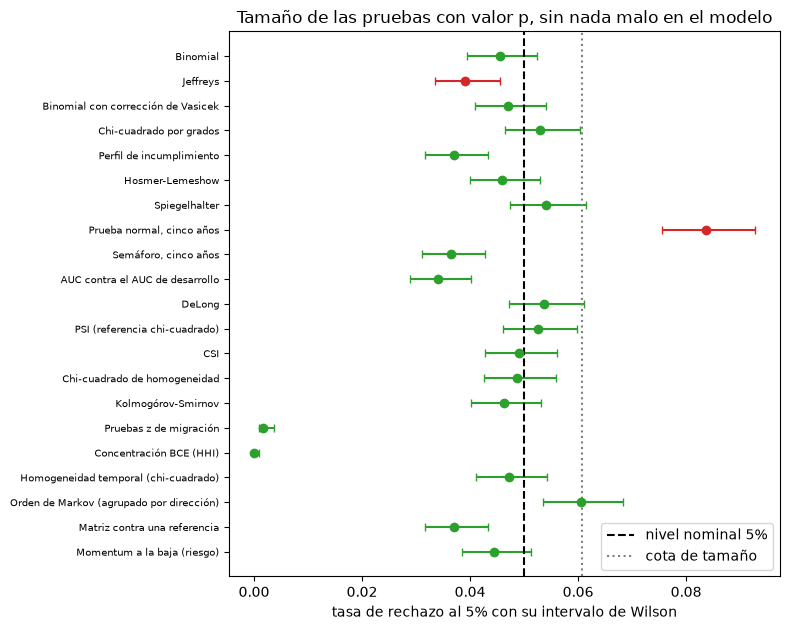

In [4]:
# Decidir para cada prueba si mantiene su tamaño en ambos niveles, contar y dibujar las tasas al 5%
from riskvalidation.harness import Rate, within_size

holds = {}
for key in null_keys:
    row = rows[key]
    verdicts = []
    for alpha in out["levels"]:
        rule = f"p<{alpha:g}"
        if row["exact"] is not None:
            verdicts.append(row["exact"][rule] <= alpha + 1e-12)
        else:
            c = row["rates"][rule]
            verdicts.append(within_size(Rate(c["rejections"], c["n"]), alpha))
    holds[key] = all(verdicts)

reported = null["impact"]["tests_within_bound"]["value"]
print("pruebas que mantienen su tamaño al 5% y al 1%:", sum(holds.values()), "de", len(holds), "|", "reportado por el caso:", int(reported))
print("cotas de tamaño de 4000 repeticiones:", {rule: round(bound, 4) for rule, bound in out["size_bounds"].items()})
for key, ok in holds.items():
    if not ok:
        print("no mantiene:", rows[key]["label"][LANG])

fig, ax = plt.subplots(figsize=(8, 6.4))
for i, key in enumerate(null_keys):
    c = rows[key]["rates"]["p<0.05"]
    ax.errorbar(c["rate"], i, xerr=[[c["rate"] - c["wilson_low"]], [c["wilson_high"] - c["rate"]]], fmt="o", capsize=3,
                color="tab:green" if holds[key] else "tab:red")
ax.axvline(0.05, color="black", linestyle="--", label="nivel nominal 5%")
ax.axvline(out["size_bounds"]["p<0.05"], color="gray", linestyle=":", label="cota de tamaño")
ax.set_yticks(range(len(null_keys)))
ax.set_yticklabels([rows[key]["label"][LANG] for key in null_keys], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("tasa de rechazo al 5% con su intervalo de Wilson")
ax.set_title("Tamaño de las pruebas con valor p, sin nada malo en el modelo")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Paso 3: toda la distribución del valor p

Con una prueba continua exacta, el valor p es uniforme en $[0,1]$ cuando la nula se cumple, así que un histograma de 4.000 valores p es plano y su primer intervalo cuenta los rechazos al 5%. Una prueba puede mantener su tamaño al 5% y estar mal en otra parte, y una prueba discreta o unilateral no dibuja un histograma plano por diseño. El artefacto guarda el histograma de 20 intervalos de cada fila. La celda siguiente dibuja ocho; la línea discontinua es la expectativa plana, 200 por intervalo.

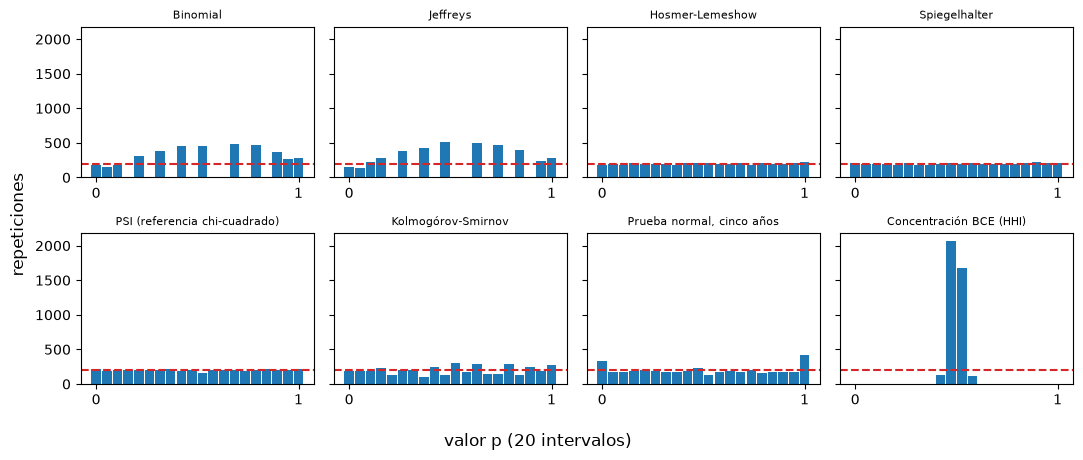

In [5]:
# Dibujar los histogramas de valores p versionados de ocho pruebas contra la expectativa plana
shown = ("pd.binomial@null", "pd.jeffreys@null", "pd.hosmer_lemeshow@null", "pd.spiegelhalter@null",
         "stability.psi@null", "stability.ks@null", "pd.normal_multiperiod@null", "rating.hhi@null")
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for ax, key in zip(axes.ravel(), shown):
    histogram = rows[key]["p_histogram"]
    ax.bar(range(len(histogram)), histogram, width=0.9, color="tab:blue")
    ax.axhline(sum(histogram) / len(histogram), color="tab:red", linestyle="--")
    ax.set_title(rows[key]["label"][LANG], fontsize=8)
    ax.set_xticks([0, len(histogram) - 1])
    ax.set_xticklabels(["0", "1"])
fig.supxlabel("valor p (20 intervalos)")
fig.supylabel("repeticiones")
fig.tight_layout()
plt.show()

### Paso 4: por qué Hosmer-Lemeshow con $G-2$ rechaza a un modelo correcto

El estadístico de Hosmer-Lemeshow agrupa a los deudores en $G$ grupos por PD predicha y suma las brechas estandarizadas entre incumplimientos observados y esperados (Hosmer y Lemeshow, 1980). Su distribución de referencia depende de cómo se obtuvieron las PD:

- para PD **ajustadas con las mismas observaciones**, el estadístico original en la muestra, $\chi^2$ con $G-2$ grados de libertad;
- para PD **dadas antes de los resultados**, que es el caso del validador, la brecha estandarizada de cada grupo es asintóticamente un $\chi^2_1$ independiente (el argumento que hace BCBS WP14 para su prueba chi-cuadrado por grados), así que la referencia es $\chi^2_G$.

El motor documenta ambas opciones en `pd_hosmer_lemeshow` (`fitted=False` usa $G$, `fitted=True` usa $G-2$). Si el estadístico se parece a $\chi^2_{G}$ en una muestra de validación, un umbral de $G-2$ queda demasiado bajo, y el tamaño que produce es una probabilidad de cola que podemos calcular: $P(\chi^2_{10} > \chi^2_{8,\,1-\alpha})$. La celda siguiente la calcula con SciPy y la pone junto a las dos filas versionadas.

In [6]:
# Probabilidad de cola de chi-cuadrado(10) más allá del valor crítico de chi-cuadrado(8), junto a los tamaños versionados
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    wrong_reference = stats.chi2.sf(stats.chi2.ppf(1 - alpha, 8), 10)
    given = rows["pd.hosmer_lemeshow@null"]["rates"][rule]
    fitted = rows["pd.hosmer_lemeshow@fitted"]["rates"][rule]
    print(f"nivel {alpha:.2f} | umbral G-2 sobre un estadístico chi-cuadrado(10) {wrong_reference:.4f} | medido con G-2 {fitted['rate']:.4f} (SE {fitted['se']:.4f}) | medido con G {given['rate']:.4f} (SE {given['se']:.4f})")

nivel 0.05 | umbral G-2 sobre un estadístico chi-cuadrado(10) 0.1146 | medido con G-2 0.1098 (SE 0.0049) | medido con G 0.0460 (SE 0.0033)
nivel 0.01 | umbral G-2 sobre un estadístico chi-cuadrado(10) 0.0284 | medido con G-2 0.0338 (SE 0.0029) | medido con G 0.0097 (SE 0.0016)


Las filas versionadas son 4.000 repeticiones de `LogisticPortfolio(n=5000)`, un modelo logístico de 5.000 deudores cuyas PD son exactamente correctas. La celda siguiente sortea un conjunto de ese generador, reconstruido desde la configuración del artefacto, y corre la prueba del motor de las dos maneras sobre él, de modo que la única diferencia son los grados de libertad que el motor registra en el resultado.

In [7]:
# Sortear un conjunto del generador versionado y correr la prueba del motor con G y con G-2 grados de libertad
from riskvalidation.generators import LogisticPortfolio
from riskvalidation.validation import pd_hosmer_lemeshow

logit = LogisticPortfolio(**out["generators"]["logistic-5000"]["config"])
draw = logit.draw(np.random.default_rng(2024))
for fitted in (False, True):
    result = pd_hosmer_lemeshow(draw["defaults"], draw["pd"], fitted=fitted)
    print(f"fitted: {'sí' if fitted else 'no':2s} | estadístico {result.statistic:.4f} | grados de libertad {result.extras['dof']} | valor p {result.p_value:.4f}")
print("incumplimientos en el conjunto:", int(np.sum(draw["defaults"])), "de", len(draw["defaults"]))

fitted: no | estadístico 9.7179 | grados de libertad 10 | valor p 0.4656
fitted: sí | estadístico 9.7179 | grados de libertad 8 | valor p 0.2854
incumplimientos en el conjunto: 262 de 5000


El mismo estadístico da un valor p menor con menos grados de libertad, y ese es todo el mecanismo. La celda siguiente repite la fila versionada `@fitted`, semilla incluida (unos tres segundos), para confirmar que los 439 rechazos al 5% son lo que da el motor hoy.

In [8]:
# Repetir la fila versionada fitted=True con su semilla y comparar los rechazos
from riskvalidation.harness import simulate

row = rows["pd.hosmer_lemeshow@fitted"]
replay = simulate(row["test_id"], logit, n_rep=row["n_rep"], seed=row["seed"], test_kwargs={"fitted": True})
for rule in ("p<0.05", "p<0.01"):
    print(f"{rule} | repetición {replay.rates[rule].rejections} | versionado {row['rates'][rule]['rejections']}")
print("calculada por", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

p<0.05 | repetición 439 | versionado 439
p<0.01 | repetición 135 | versionado 135
calculada por 0.4.3 | instalado 0.9.0


### Paso 5: por qué la prueba normal en cinco años rechaza a un modelo correcto

La prueba normal multiperíodo de WP14 suma las diferencias anuales entre la tasa de incumplimiento observada y la PD, $e_t = d_t - \mathrm{PD}_t$, y divide por una estimación de su dispersión:

$$S = \frac{\sum_t e_t}{\sqrt{T}\,\hat\sigma}, \qquad \hat\sigma^2 = \frac{1}{T-1}\Big(\sum_t e_t^2 - \frac{1}{T}\big(\sum_t e_t\big)^2\Big)$$

y compara $S$ con la cola superior de la normal estándar. El código de `pd_normal_multiperiod` muestra que $\hat\sigma$ es la desviación estándar muestral de las $T$ diferencias anuales, de modo que $S = \sqrt{T}\,\bar e / \hat\sigma$ es el estadístico $t$ de una muestra con $T-1$ grados de libertad. Con $T = 5$ años tiene cuatro grados de libertad, y sus colas son más pesadas que las de la normal que usa la prueba. Si esa es la causa, el tamaño debería ser la cola de $t_4$ más allá del valor crítico normal. La celda siguiente calcula esa cola y la pone junto a las tasas versionadas. La concordancia es una verificación de consistencia, no una identidad: las diferencias anuales son conteos escalados, no exactamente normales.

In [9]:
# Cola de la distribución t con cuatro grados de libertad más allá del valor crítico normal, junto a los tamaños versionados
row = rows["pd.normal_multiperiod@null"]
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    critical = stats.norm.isf(alpha)
    t_tail = stats.t.sf(critical, 4)
    c = row["rates"][rule]
    gap = (c["rate"] - t_tail) / np.sqrt(t_tail * (1 - t_tail) / c["n"])
    print(f"nivel {alpha:.2f} | valor crítico normal {critical:.4f} | cola t(4) {t_tail:.4f} | medido {c['rate']:.4f} (SE {c['se']:.4f}) | z {gap:+.2f}")

nivel 0.05 | valor crítico normal 1.6449 | cola t(4) 0.0877 | medido 0.0838 (SE 0.0044) | z -0.88
nivel 0.01 | valor crítico normal 2.3263 | cola t(4) 0.0403 | medido 0.0405 (SE 0.0031) | z +0.07


### Paso 6: la prueba de semáforo y su regla de empates

La prueba de semáforo colorea cada año por su tasa de incumplimiento estandarizada y rechaza cuando el perfil de colores es suficientemente malo. Un año con exactamente el número esperado de incumplimientos queda sobre una frontera de color, y el motor ofrece dos reglas para eso (`ties="lower"`, la asignación impresa, y `ties="upper"`, la que usó la propia simulación de WP14). Ambas son cálculos exactos, sin simulación, y el motor los expone como `traffic_lights_rejection_probability`. La celda siguiente calcula el tamaño exacto de las dos reglas para cinco años independientes de 1.000 deudores con PD de 3%, y compara la primera con la fila versionada. La fila `@upper` del panel de ajustes lleva la segunda.

In [10]:
# Tamaño exacto de la prueba de semáforo con las dos reglas de empates, junto a los valores exactos versionados
from riskvalidation.harness import traffic_lights_rejection_probability

for ties, key in (("lower", "pd.traffic_lights@null"), ("upper", "pd.traffic_lights@upper")):
    for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
        exact = traffic_lights_rejection_probability([1000] * 5, 0.03, alpha, pd_true=0.03, ties=ties)["probability"]
        c = rows[key]["rates"][rule]
        print(f"ties={ties:5s} | nivel {alpha:.2f} | exacto {exact:.4f} | exacto versionado {rows[key]['exact'][rule]:.4f} | simulado {c['rate']:.4f}")

ties=lower | nivel 0.05 | exacto 0.0379 | exacto versionado 0.0379 | simulado 0.0365
ties=lower | nivel 0.01 | exacto 0.0074 | exacto versionado 0.0074 | simulado 0.0035
ties=upper | nivel 0.05 | exacto 0.0603 | exacto versionado 0.0603 | simulado 0.0635
ties=upper | nivel 0.01 | exacto 0.0113 | exacto versionado 0.0113 | simulado 0.0140


### Paso 7: los ajustes que importan

El panel `settings` guarda las filas que el arnés agregó porque un valor por defecto resultó importar: los grados de libertad de Hosmer-Lemeshow (paso 4), la regla de empates (paso 6), un mejor grado que espera menos de un incumplimiento, el AUC de desarrollo estimado en lugar de conocido, la prueba de orden con 20.000 repeticiones, y el PSI con muestras de 100 juzgado por sus dos reglas empíricas. La celda siguiente imprime sus tasas; las reglas empíricas aparecen como `metric>0.1` y `metric>0.25`.

In [11]:
# Imprimir las tasas del panel de ajustes, con las reglas empíricas del PSI cuando existen
setting_note = {
    "fitted": "G - 2 grados de libertad (con fitted activado)",
    "upper": "la regla de empates superior que usó la simulación de WP14",
    "thin": "un mejor grado que espera menos de un incumplimiento",
    "dev1": "el AUC de desarrollo estimado en una muestra igual (forma BCE)",
    "dev1-extended": "lo mismo sumando la varianza de desarrollo",
    "null-20000": "la prueba de orden con 20000 repeticiones",
    "n100": "dos muestras de 100 con las reglas empíricas del PSI",
}
for key, row in rows.items():
    if row["panel"] != "settings":
        continue
    parts = [f"{rule} {row['rates'][rule]['rate']:.4f}" for rule in row["rates"]]
    print(f"{key:36s} n_rep {row['n_rep']:6d} | " + " | ".join(parts))
    print(f"   {setting_note[key.split('@')[1]]}")

pd.hosmer_lemeshow@fitted            n_rep   4000 | p<0.05 0.1098 | p<0.01 0.0338
   G - 2 grados de libertad (con fitted activado)
pd.traffic_lights@upper              n_rep   4000 | p<0.05 0.0635 | p<0.01 0.0140
   la regla de empates superior que usó la simulación de WP14
pd.chi2_grades@thin                  n_rep   4000 | p<0.05 0.0568 | p<0.01 0.0173
   un mejor grado que espera menos de un incumplimiento
disc.auc_vs_initial@dev1             n_rep   4000 | p<0.05 0.1158 | p<0.01 0.0452
   el AUC de desarrollo estimado en una muestra igual (forma BCE)
disc.auc_vs_initial@dev1-extended    n_rep   4000 | p<0.05 0.0530 | p<0.01 0.0105
   lo mismo sumando la varianza de desarrollo
rating.markov_order@null-20000       n_rep  20000 | p<0.05 0.0505 | p<0.01 0.0106
   la prueba de orden con 20000 repeticiones
stability.psi@n100                   n_rep   4000 | p<0.05 0.0698 | p<0.01 0.0205 | metric>0.1 0.8498 | metric>0.25 0.2285
   dos muestras de 100 con las reglas empíricas del PSI


### Paso 8: una métrica descriptiva cuando el modelo es correcto

No toda salida del motor es una prueba. El AUC y el ECE son estimaciones, y un validador las lee con sus propias medidas de desempeño: sesgo, error estándar empírico, el error estándar del modelo del motor y la cobertura de su intervalo, cada una con un error de Monte Carlo (Morris, White y Crowther, 2019, Tabla 6). El artefacto guarda dos: el AUC con su error estándar del BCE sobre puntajes binormales de AUC conocido, y el ECE sobre un modelo cuyas PD son exactamente correctas, donde la verdad es 0. La celda siguiente las imprime. La celda posterior recalcula el desempeño del AUC con 400 sorteos nuevos y la función `estimator_performance` del motor, para mostrar la llamada, no para reemplazar los 4.000 versionados.

In [12]:
# Imprimir las medidas de desempeño versionadas del AUC y del ECE cuando el modelo es correcto
auc = out["estimators"]["auc"]
ece = out["estimators"]["ece_when_right"]
print("AUC, repeticiones:", auc["n"], "|", "verdad:", round(auc["truth"], 5))
print(f"  sesgo {auc['bias']:+.5f} (MCSE {auc['bias_mcse']:.5f}) | EE empírico {auc['empirical_se']:.5f} | EE del modelo {auc['model_se']:.5f} ({auc['model_se_relative_error_pct']:+.2f}% ± {auc['model_se_relative_error_mcse_pct']:.2f})")
print(f"  cobertura del intervalo de 95% {auc['coverage']:.4f} (MCSE {auc['coverage_mcse']:.4f})")
print("ECE cuando las PD son correctas, repeticiones:", ece["n"], "|", "verdad:", ece["truth"])
print(f"  media {ece['mean']:.5f} | sesgo {ece['bias']:+.5f} (MCSE {ece['bias_mcse']:.5f}) | RMSE {ece['rmse']:.5f}")

AUC, repeticiones: 4000 | verdad: 0.80193
  sesgo +0.00074 (MCSE 0.00028) | EE empírico 0.01790 | EE del modelo 0.01788 (-0.15% ± 1.12)
  cobertura del intervalo de 95% 0.9395 (MCSE 0.0038)
ECE cuando las PD son correctas, repeticiones: 1000 | verdad: 0.0
  media 0.00672 | sesgo +0.00672 (MCSE 0.00006) | RMSE 0.00694


Los números versionados vienen de 4.000 repeticiones. La celda siguiente muestra la llamada del motor sobre 400 sorteos nuevos del mismo generador: el AUC y su error estándar del BCE desde `auc_with_variance`, y luego `estimator_performance` con el error estándar del modelo y el intervalo de 95%. Menos sorteos dan errores de Monte Carlo mayores, y la función de desempeño los reporta.

In [13]:
# Recalcular el desempeño del AUC con 400 sorteos nuevos del generador versionado con estimator_performance
from riskvalidation.generators import BinormalScores
from riskvalidation.harness import estimator_performance
from riskvalidation.validation.discrimination import auc_with_variance

binormal = BinormalScores(**out["generators"]["binormal-150"]["config"])
estimates, model_se = [], []
for child in np.random.SeedSequence(11).spawn(400):
    sample = binormal.draw(np.random.default_rng(child))
    auc_hat, variance, _, _ = auc_with_variance(sample["risk"], sample["defaults"])
    estimates.append(auc_hat)
    model_se.append(np.sqrt(variance))

estimates, model_se = np.array(estimates), np.array(model_se)
fresh = estimator_performance(estimates, binormal.truth()["auc_current"], model_se=model_se,
                              lower=estimates - 1.96 * model_se, upper=estimates + 1.96 * model_se)
print("sorteos nuevos:", fresh["n"], "|", "sesgo", f"{fresh['bias']:+.5f} (MCSE {fresh['bias_mcse']:.5f})", "|", "cobertura", f"{fresh['coverage']:.4f} (MCSE {fresh['coverage_mcse']:.4f})")
print("error relativo del EE del modelo:", f"{fresh['model_se_relative_error_pct']:+.2f}% ± {fresh['model_se_relative_error_mcse_pct']:.2f}")

sorteos nuevos: 400 | sesgo -0.00038 (MCSE 0.00094) | cobertura 0.9350 (MCSE 0.0123)
error relativo del EE del modelo: -4.57% ± 3.40


## Resultados

- **Diecinueve de veintiuna pruebas mantienen su tamaño al 5% y al 1%.** El recálculo da el conteo que reporta el caso. Las dos que no lo hacen son la prueba de Jeffreys y la prueba normal en cinco años. La de Jeffreys está en rojo en la figura por su nivel de 1%: la probabilidad exacta de que rechace al 1% con 1.000 deudores y PD de 1% es 1,38%, sobre 1%, aunque su tasa simulada al 5% (3,90%) queda bajo el nivel nominal. La prueba normal en cinco años rechaza 8,38% al 5% y 4,05% al 1%, fuera de la cota de 6,06% y 1,49%.
- **Dos pruebas mantienen su tamaño siendo conservadoras, no calibradas.** Las pruebas z de migración rechazan 0,18% al 5% y la prueba de concentración del BCE 0,00%. El histograma de la prueba de concentración muestra por qué: sus valores p se amontonan alrededor de un medio, así que casi nunca llega a un valor p pequeño ni siquiera ante un cambio. Mantener el tamaño no dice nada de la potencia, y el cuaderno 06 mide ambos.
- **Los histogramas separan lo que las tasas no pueden.** Hosmer-Lemeshow, Spiegelhalter y el PSI dibujan histogramas planos. Las pruebas binomial y de Jeffreys dibujan grumos y vacíos porque un conteo de incumplimientos toma pocos valores, y por eso su tamaño exacto no es el nivel nominal. La prueba normal tiene masa extra en el primer y el último intervalo, la firma de un estadístico comparado con una distribución demasiado liviana.
- **Las dos fallas tienen mecanismos que verificamos.** Hosmer-Lemeshow con $G-2$ grados de libertad sobre PD fijadas antes de los resultados rechazaría en la cola de un $\chi^2_{10}$ más allá del valor crítico de $\chi^2_8$: 11,46% al 5% y 2,84% al 1%, frente a 10,98% y 3,38% medidos. El valor por defecto del motor para PD dadas es $G$ grados de libertad, que mide 4,60% y 0,97%. El mismo estadístico sobre un conjunto sorteado da p 0,466 con 10 grados de libertad y 0,285 con 8. La prueba normal es un estadístico $t$ de una muestra con cuatro grados de libertad comparado con valores críticos normales: la cola de $t_4$ más allá del valor crítico normal es 8,77% al 5% y 4,03% al 1%, frente a 8,38% y 4,05% medidos (brechas de -0,88 y +0,07 errores estándar). Eso es consistente con la causa, no una prueba de ella.
- **Un valor por defecto también es una medición.** El tamaño exacto del semáforo es 3,79% al 5% con la regla de empates impresa y 6,03% con la regla superior, la que usó la simulación de WP14. Un chi-cuadrado por grados cuyo mejor grado espera 0,6 incumplimientos rechaza 5,68% al 5% y 1,73% al 1%, sobre la cota del 1%. La prueba de AUC del BCE rechaza 11,58% al 5% cuando el AUC de desarrollo se estimó con una muestra tan grande como la actual, y 5,30% cuando se suma la varianza de desarrollo. Con muestras de 100, la regla PSI 0,10 tiene una tasa de falsas alarmas de 84,98% y la regla 0,25 de 22,85%, frente a 6,98% de la referencia chi-cuadrado al 5%.
- **Una métrica que vale cero cuando el modelo es correcto no lo vale.** El ECE de un modelo correcto con 5.000 deudores promedia 0,0067, un sesgo de más de 100 errores estándar de Monte Carlo, así que un ECE pequeño no es por sí solo evidencia de descalibración. El error estándar del AUC del BCE es correcto en promedio (error relativo de -0,15% con un error de Monte Carlo de 1,12 puntos) y su intervalo de 95% cubre 93,95% (error de Monte Carlo de 0,38 puntos). Los 400 sorteos nuevos concuerdan dentro de su error mayor: un error relativo de -4,57 ± 3,40 y una cobertura de 93,50%.

Lo que este cuaderno no muestra: la potencia de ninguna prueba, qué pasa cuando el modelo está mal de una manera conocida (cuaderno 03), ni cuando los incumplimientos están correlacionados (cuaderno 04). Una prueba que mantiene su tamaño aquí lo mantiene en estos generadores y sus supuestos, no en toda cartera.

## Resumen

- El tamaño de una prueba se mide sobre datos donde su nula se cumple; una prueba mantiene su tamaño cuando su probabilidad exacta, o su tasa simulada frente a una cota unilateral, es a lo sumo el nivel.
- Diecinueve de las veintiuna pruebas con valor p mantienen su tamaño al 5% y al 1%; la prueba de Jeffreys (tamaño exacto 1,38% al 1%) y la prueba normal en cinco años (8,38% al 5%) no.
- Un histograma de valores p verifica toda la distribución: plano para las pruebas continuas, con grumos para las pruebas de conteo, pesado en ambos extremos para un estadístico comparado con una distribución demasiado liviana.
- Las dos fallas tienen mecanismos en el código del motor con los que concuerdan las tasas medidas: $G-2$ grados de libertad para PD dadas, y un estadístico $t_4$ leído contra valores críticos normales.
- Los valores por defecto son mediciones: la regla de empates del semáforo, un grado delgado, un AUC de desarrollo estimado y las reglas empíricas del PSI mueven el tamaño, y una métrica descriptiva como el ECE tiene sesgo cuando el modelo es correcto.

**Qué probar a continuación.** Cambia la semilla del conjunto sorteado en el paso 4 y repite la celda varias veces para ver cómo se mueven juntos los valores p con $G$ y $G-2$; luego lee el cuaderno 03, que planta defectos y mide la potencia.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la prueba normal multiperíodo, la prueba de semáforo y la prueba chi-cuadrado por grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 a 2.5.5 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.